<a href="https://colab.research.google.com/github/houmanhaghi/Gold3n-mind/blob/AI-Estimator/gold3n_mind.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pursose**


combination of
  * Buying Au Formula
  * AI Estimation Market

## Buying Au Formula

## AI Estimation Market

In [ ]:
! pip install persiantools

In [ ]:
import requests
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from persiantools.jdatetime import JalaliDate
from datetime import timedelta
from datetime import datetime, timedelta

In [ ]:
csv_name = str()

### Data Mining

In [ ]:
# today = JalaliDate.today().strftime("%Y-%m-%d")

# url = f"https://api.navasan.tech/ohlcSearch/?api_key=freerPVwKRSCRE1qK2YztQ03toKrnDte&item=18ayar&start=1397-01-01&end={today}"

# response = requests.get(url)
# data = response.json()

In [ ]:
original_data = data.copy()

In [ ]:
df = pd.DataFrame(data)
df = df.drop(columns=['timestamp'])
df = df.drop_duplicates(subset='date', keep='first')
df = df.reset_index(drop=True)
df = df.sort_values(by='date')

In [ ]:
df['gregorian_date'] = df['date'].apply(lambda x: JalaliDate(int(x[:4]), int(x[5:7]), int(x[8:10])).to_gregorian())
df['gregorian_date'] = pd.to_datetime(df['gregorian_date'])

In [ ]:
df.head()

,date,open,high,low,close,gregorian_date
0,1398-03-19,406297,410000,406297,410000,2019-06-09
1,1398-03-20,410000,415300,407900,415300,2019-06-10
2,1398-03-21,415300,415300,410900,411600,2019-06-11
3,1398-03-22,411600,414600,411143,414600,2019-06-12
4,1398-03-23,414600,428900,414600,428900,2019-06-13


In [ ]:
df.tail()

,date,open,high,low,close,gregorian_date
1973,1403-09-09,4561610,4561610,4561610,4561610,2024-11-29
1974,1403-09-10,4561610,4648410,4561610,4577080,2024-11-30
1975,1403-09-11,4577080,4603860,4544300,4564380,2024-12-01
1976,1403-09-12,4564380,4594630,4560460,4587470,2024-12-02
1977,1403-09-13,4587470,4645870,4580080,4622330,2024-12-03


In [ ]:
csv_name = f"gold-grm18ayar-iran?start={df[df.index==0]['date'].values[0]}&end={df[df.index==max(df.index)]['date'].values[0]}.csv"
df.to_csv(csv_name, index=False)

In [ ]:
original_df = df.copy()

### R&D Estimation

In [ ]:
df = pd.read_csv(csv_name)

In [ ]:
days_ago = JalaliDate.today() - timedelta(days=180)
days_ago = days_ago.strftime("%Y-%m-%d")

train_data = df[df['date'] <  days_ago][['gregorian_date','close']]
test_data  = df[df['date'] >= days_ago][['gregorian_date','close']]

In [ ]:
train_data['gregorian_date'] = pd.to_datetime(train_data['gregorian_date'], errors='coerce')
test_data['gregorian_date'] = pd.to_datetime(test_data['gregorian_date'], errors='coerce')

train_data = train_data.dropna(subset=['gregorian_date'])
test_data = test_data.dropna(subset=['gregorian_date'])

train_data['close'] = pd.to_numeric(train_data['close'], errors='coerce')
test_data['close'] = pd.to_numeric(test_data['close'], errors='coerce')

train_data = train_data.dropna(subset=['close'])
test_data = test_data.dropna(subset=['close'])

In [ ]:
train_data.tail()

,gregorian_date,close
1792,2024-06-01,3334640
1793,2024-06-02,3393510
1794,2024-06-03,3393510
1795,2024-06-04,3393510
1796,2024-06-05,3358880


In [ ]:
test_data.tail()

,gregorian_date,close
1973,2024-11-29,4561610
1974,2024-11-30,4577080
1975,2024-12-01,4564380
1976,2024-12-02,4587470
1977,2024-12-03,4622330


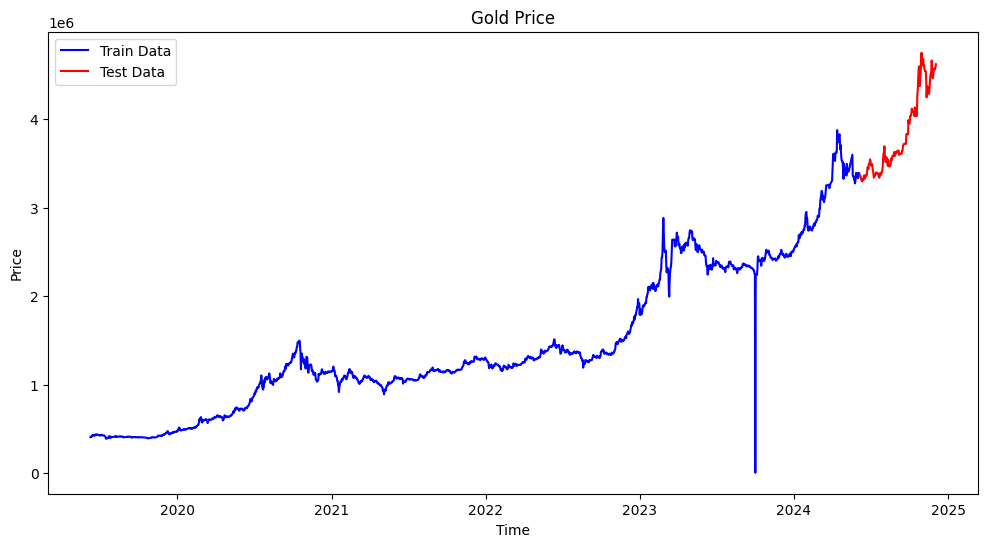

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(train_data['gregorian_date'],
         train_data['close'],
         label='Train Data', color='blue')

plt.plot(test_data['gregorian_date'],
         test_data['close'],
         label='Test Data', color='red')

plt.xlabel('Time')
plt.ylabel('Price')
plt.title('Gold Price')
plt.legend()
plt.show()

In [ ]:
scaler = MinMaxScaler()
train_data_scaled = scaler.fit_transform(train_data[['close']].values)
test_data_scaled = scaler.transform(test_data[['close']].values)

#### train

In [ ]:
lookback = 60  # Number of previous data points to consider
def create_dataset(dataset, look_back=lookback):
    X, Y = [], []
    for i in range(len(dataset)-look_back-1):
        a = dataset[i:(i+look_back), 0]
        X.append(a)
        Y.append(dataset[i + look_back, 0])
    return np.array(X), np.array(Y)

X_train, y_train = create_dataset(train_data_scaled)
X_test, y_test = create_dataset(test_data_scaled)

X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))


In [ ]:
# class LSTM(nn.Module):
#     def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
#         super(LSTM, self).__init__()
#         self.hidden_dim = hidden_dim
#         self.num_layers = num_layers

#         self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
#         self.fc = nn.Linear(hidden_dim, output_dim)

#     def forward(self, x):
#         h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
#         c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
#         out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
#         out = self.fc(out[:, -1, :])
#         return out

# input_dim = 1
# hidden_dim = 50
# num_layers = 1
# output_dim = 1
# model = LSTM(input_dim, hidden_dim, num_layers, output_dim)

class ImprovedLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(ImprovedLSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True, dropout=0.5)  # added dropout
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])
        return out

# Try more layers and/or higher neurons
model = ImprovedLSTM(input_dim=1, hidden_dim=400, num_layers=5, output_dim=1)


loss_fn = torch.nn.MSELoss()
optimiser = torch.optim.Adam(model.parameters(), lr=0.001)


In [ ]:
num_epochs = 200
X_train_tensor = torch.from_numpy(X_train).type(torch.Tensor)
y_train_tensor = torch.from_numpy(y_train).type(torch.Tensor)
for t in range(num_epochs):
    y_train_pred = model(X_train_tensor)
    loss = loss_fn(y_train_pred, y_train_tensor.view(-1, 1))
    optimiser.zero_grad()
    loss.backward()
    optimiser.step()

In [ ]:
X_test_tensor = torch.from_numpy(X_test).type(torch.Tensor)
y_test_pred = model(X_test_tensor)

y_test_pred = scaler.inverse_transform(y_test_pred.detach().numpy())
y_test = scaler.inverse_transform([y_test])
plt.figure(figsize=(12,6))
plt.plot(y_test[0], label='Actual')
plt.plot(y_test_pred, label='Predicted')
plt.legend()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
info = """
R&D
days_ago ~ 180
lookback ~ 60
model ImprovedLSTM:
  dropout ~ 0.6
  input_dim ~ 1
  hidden_dim ~ 4000
  num_layers ~ 5
  output_dim ~ 1
lr ~ 0.001
num_epochs ~ 200
"""
plt.savefig(f'{info}.png', dpi=300)
plt.savefig(f'/content/drive/MyDrive/gold3n-mind/AI-estimates/{info}.png', dpi=300)
plt.close()

In [ ]:
# Save the entire model (architecture + weights)
torch.save(model, f'{info}.pth')

# # Load the entire model
# model = torch.load(f'{info}.pth')
# model.eval()

The Best HyperParameters Results

```
days_ago ~ 150
lookback ~ 30
model ImprovedLSTM:
  dropout ~ 0.4
  input_dim=1
  hidden_dim=250
  num_layers=3
  output_dim=1
lr=0.001
num_epochs ~ 100
```

### Market Estimation

In [ ]:
!pip install ipywidgets

In [ ]:
processing_data = df[df['date'] >= '1381-05-16'][['gregorian_date','close']]

In [ ]:
processing_data

,gregorian_date,close
0,2019-06-09,410000
1,2019-06-10,415300
2,2019-06-11,411600
3,2019-06-12,414600
4,2019-06-13,428900
...,...,...
1973,2024-11-29,4561610
1974,2024-11-30,4577080
1975,2024-12-01,4564380
1976,2024-12-02,4587470


In [ ]:
processing_data['gregorian_date'] = pd.to_datetime(processing_data['gregorian_date'], errors='coerce')
processing_data = processing_data.dropna(subset=['gregorian_date'])
processing_data['close'] = pd.to_numeric(processing_data['close'], errors='coerce')
processing_data = processing_data.dropna(subset=['close'])

In [ ]:
processing_data

,gregorian_date,close
0,2019-06-09,410000
1,2019-06-10,415300
2,2019-06-11,411600
3,2019-06-12,414600
4,2019-06-13,428900
...,...,...
1973,2024-11-29,4561610
1974,2024-11-30,4577080
1975,2024-12-01,4564380
1976,2024-12-02,4587470


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import ipywidgets as widgets

dates = np.array(processing_data['gregorian_date'])
prices = np.array(processing_data['close'])


plt.figure(figsize=(12, 6))
plt.plot(dates, prices, label='Gold Prices', color='green')
plt.xlabel('Time')
plt.ylabel('Price')
plt.title('Gold Price Plot')

slider = widgets.IntSlider(value=0, min=0, max=len(dates)-1, step=1, description='Select Point:')

def update_plot(index):
    plt.clf()
    plt.plot(dates, prices, label='Gold Prices', color='green')
    plt.scatter(dates[index], prices[index], color='red', zorder=5)
    plt.xlabel('Time')
    plt.ylabel('Price')
    plt.title('Gold Price Plot')
    plt.legend()
    plt.show()


widgets.interactive(update_plot, index=slider)


interactive(children=(IntSlider(value=0, description='Select Point:', max=1977), Output()), _dom_classes=('wid…

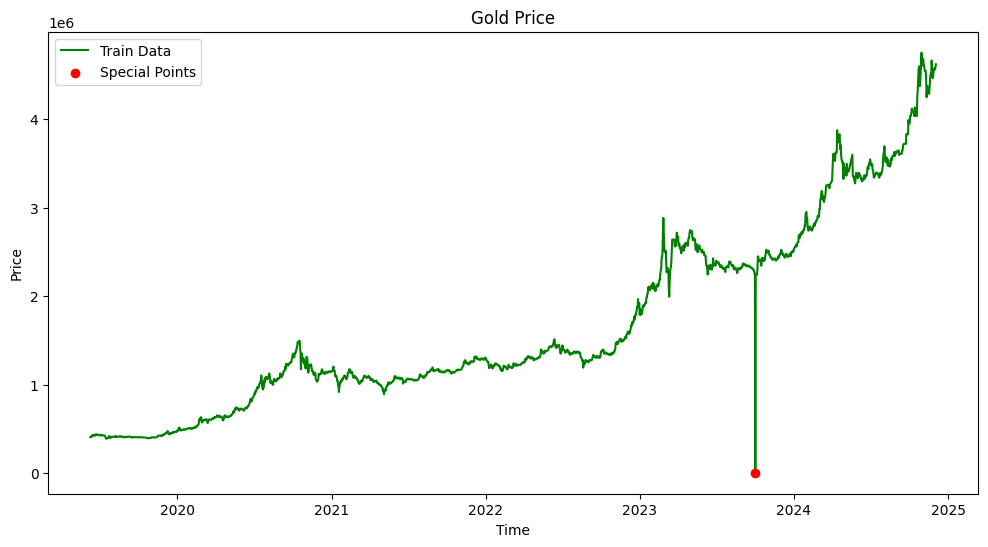

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

plt.plot(processing_data['gregorian_date'],
         processing_data['close'],
         label='Train Data', color='green')

indexes_to_delete = [1565]
special_dates = processing_data['gregorian_date'].iloc[indexes_to_delete]
special_prices = processing_data['close'].iloc[indexes_to_delete]
plt.scatter(special_dates, special_prices, color='red', label='Special Points', zorder=5)

# for idx, date, price in zip(indexes_to_delete, special_dates, special_prices):
#     plt.text(date, price, f'({idx}: {date}, {price})', fontsize=9, color='blue', rotation=45)

plt.xlabel('Time')
plt.ylabel('Price')
plt.title('Gold Price')
plt.legend()
plt.show()


In [ ]:
processing_data = processing_data.drop(indexes_to_delete, axis=0).reset_index(drop=True)

In [ ]:
scaler = MinMaxScaler()
processing_data_scaled = scaler.fit_transform(processing_data[['close']].values)

In [ ]:
lookback = 90
def create_dataset(dataset, look_back=lookback):
    X, Y = [], []
    for i in range(len(dataset)-look_back-1):
        a = dataset[i:(i+look_back), 0]
        X.append(a)
        Y.append(dataset[i + look_back, 0])
    return np.array(X), np.array(Y)


X_final, y_final = create_dataset(processing_data_scaled)
X_final = np.reshape(X_final, (X_final.shape[0], X_final.shape[1], 1))
X_final_tensor = torch.from_numpy(X_final).type(torch.Tensor)
y_final_tensor = torch.from_numpy(y_final).type(torch.Tensor)

In [ ]:
# class LSTMWithDropout(nn.Module):
#     def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
#         super(LSTMWithDropout, self).__init__()
#         self.hidden_dim = hidden_dim
#         self.num_layers = num_layers

#         # Adding a bidirectional LSTM layer
#         self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True, bidirectional=True)

#         # Adding a dropout layer
#         self.dropout = nn.Dropout(p=0.2)  # 20% dropout

#         self.fc = nn.Linear(hidden_dim * 2, output_dim)  # *2 for bidirectional LSTM

#     def forward(self, x):
#         h0 = torch.zeros(self.num_layers * 2, x.size(0), self.hidden_dim).requires_grad_()  # *2 for bidirectional
#         c0 = torch.zeros(self.num_layers * 2, x.size(0), self.hidden_dim).requires_grad_()  # *2 for bidirectional
#         out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
#         out = self.dropout(out)
#         out = self.fc(out[:, -1, :])  # Get the output of the last time step
#         return out

# input_dim = 1
# hidden_dim = 50
# num_layers = 1
# output_dim = 1
# model = LSTM(input_dim, hidden_dim, num_layers, output_dim)


# New LSTM Model with more layers and increased neurons
class ImprovedLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(ImprovedLSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True, dropout=0.2)  # added dropout
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])
        return out

# Try more layers and/or higher neurons
model = ImprovedLSTM(input_dim=1, hidden_dim=100, num_layers=2, output_dim=1)





loss_fn = torch.nn.MSELoss()
optimiser = torch.optim.Adam(model.parameters(), lr=0.001)


In [ ]:
num_epochs = 100
for t in range(num_epochs):
    y_final_pred = model(X_final_tensor)
    loss = loss_fn(y_final_pred, y_final_tensor.view(-1, 1))
    optimiser.zero_grad()
    loss.backward()
    optimiser.step()

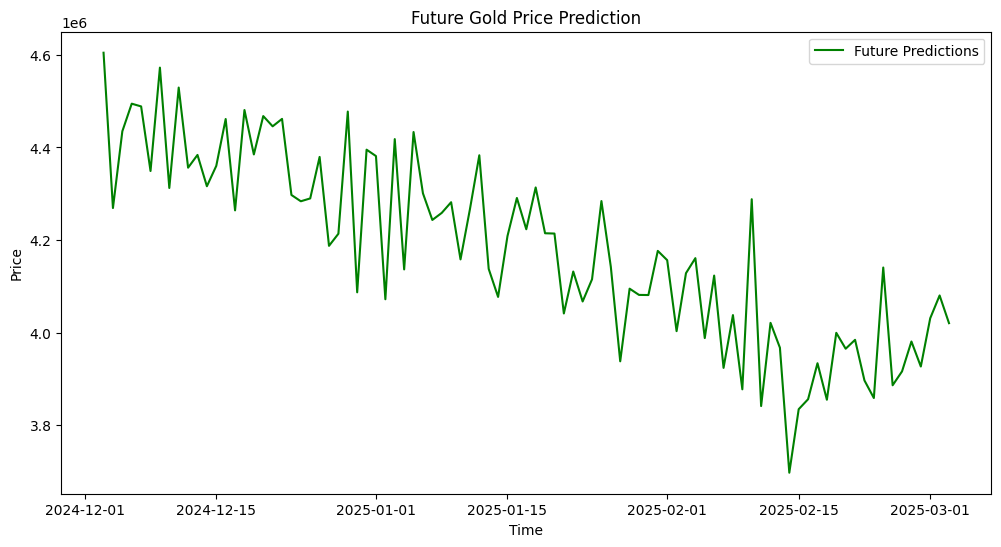

In [ ]:
from datetime import datetime, timedelta

eng_today = datetime.today()
date_list = [eng_today + timedelta(days=i) for i in range(91)]

future_data = pd.DataFrame({
    'gregorian_date': [date.strftime('%Y-%m-%d') for date in date_list],
    'close': [0] * 91
})

# Convert the future data to the same format as the training data
future_data['gregorian_date'] = pd.to_datetime(future_data['gregorian_date'], errors='coerce')
future_data = future_data.dropna(subset=['gregorian_date'])

# Scale the 'close' values (all zeros initially)
future_data_scaled = scaler.transform(future_data[['close']].values)

# Start predictions using the last 'lookback' days from the test data
recent_data = train_data_scaled[-lookback:].copy()

# Placeholder for storing predicted scaled values
future_predictions_scaled = []

for i in range(len(future_data_scaled)):
    # Reshape the recent data to match the LSTM input
    input_data = torch.from_numpy(recent_data).float().view(1, lookback, 1)

    # Predict the next value
    next_pred_scaled = model(input_data).detach().numpy()

    # Append the prediction to the list
    future_predictions_scaled.append(next_pred_scaled[0, 0])

    # Update the recent data with the new prediction
    recent_data = np.vstack((recent_data[1:], [[next_pred_scaled[0, 0]]]))

# Inverse scale the predictions to get the actual prices
future_predictions = scaler.inverse_transform(np.array(future_predictions_scaled).reshape(-1, 1))

# Add predictions to the future_data DataFrame
future_data['close'] = future_predictions

# Plot the predictions
plt.figure(figsize=(12, 6))
plt.plot(future_data['gregorian_date'], future_data['close'], label='Future Predictions', color='green')
plt.xlabel('Time')
plt.ylabel('Price')
plt.title('Future Gold Price Prediction')
plt.legend()
plt.show()


In [ ]:
last_sequence = processing_data_scaled[-lookback:].reshape(1, lookback, 1)
predictions = []

for _ in range(30):
    last_sequence_tensor = torch.from_numpy(last_sequence).type(torch.Tensor)
    next_day_pred = model(last_sequence_tensor).detach().numpy()
    predictions.append(next_day_pred[0, 0])  # Collect the prediction
    # Update the last sequence with the new prediction
    last_sequence = np.append(last_sequence[:, 1:, :], next_day_pred.reshape(1, 1, 1), axis=1)

# Transform predictions back to original scale
predicted_prices = scaler.inverse_transform(np.array(predictions).reshape(-1, 1))


In [ ]:
plt.figure(figsize=(20, 6))
plt.plot(range(1, 31), predicted_prices, label='Predicted Future Prices')
plt.title("Predicted Gold Prices for the Next 30 Days")
plt.xlabel("Day")
plt.ylabel("Price")
plt.legend()
plt.show()

In [ ]:
# ### test


# processing_data = df[df['date'] < '1403-08-13'][['gregorian_date','close']]

# import pandas as pd
# from datetime import datetime, timedelta


# eng_today = datetime.today()
# date_list = [eng_today + timedelta(days=i) for i in range(91)]

# future_data = pd.DataFrame({
#     'gregorian_date': [date.strftime('%Y-%m-%d') for date in date_list],
#     'close': [0] * 91
# })




# processing_data['gregorian_date'] = pd.to_datetime(processing_data['gregorian_date'], errors='coerce')
# future_data['gregorian_date'] = pd.to_datetime(future_data['gregorian_date'], errors='coerce')

# processing_data = processing_data.dropna(subset=['gregorian_date'])
# future_data = future_data.dropna(subset=['gregorian_date'])

# processing_data['close'] = pd.to_numeric(processing_data['close'], errors='coerce')
# future_data['close'] = pd.to_numeric(future_data['close'], errors='coerce')

# processing_data = processing_data.dropna(subset=['close'])
# future_data = future_data.dropna(subset=['close'])



# plt.figure(figsize=(12, 6))

# plt.plot(processing_data['gregorian_date'],
#          processing_data['close'],
#          label='Train Data', color='blue')

# plt.plot(future_data['gregorian_date'],
#          future_data['close'],
#          label='Test Data', color='red')

# plt.xlabel('Time')
# plt.ylabel('Price')
# plt.title('Gold Price')
# plt.legend()
# plt.show()




# scaler = MinMaxScaler()
# processing_data_scaled = scaler.fit_transform(processing_data[['close']].values)
# future_data_scaled = scaler.transform(future_data[['close']].values)




# lookback = 60  # Number of previous data points to consider
# def create_dataset(dataset, look_back=lookback):
#     X, Y = [], []
#     for i in range(len(dataset)-look_back-1):
#         a = dataset[i:(i+look_back), 0]
#         X.append(a)
#         Y.append(dataset[i + look_back, 0])
#     return np.array(X), np.array(Y)

# X_train, y_train = create_dataset(processing_data_scaled)
# X_test, y_test = create_dataset(future_data_scaled)

# X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
# X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))




# class LSTM(nn.Module):
#     def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
#         super(LSTM, self).__init__()
#         self.hidden_dim = hidden_dim
#         self.num_layers = num_layers

#         self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
#         self.fc = nn.Linear(hidden_dim, output_dim)

#     def forward(self, x):
#         h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
#         c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
#         out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
#         out = self.fc(out[:, -1, :])
#         return out

# input_dim = 1
# hidden_dim = 50
# num_layers = 1
# output_dim = 1
# model = LSTM(input_dim, hidden_dim, num_layers, output_dim)

# loss_fn = torch.nn.MSELoss()
# optimiser = torch.optim.Adam(model.parameters(), lr=0.01)



# num_epochs = 100
# X_train_tensor = torch.from_numpy(X_train).type(torch.Tensor)
# y_train_tensor = torch.from_numpy(y_train).type(torch.Tensor)
# for t in range(num_epochs):
#     y_train_pred = model(X_train_tensor)
#     loss = loss_fn(y_train_pred, y_train_tensor.view(-1, 1))
#     optimiser.zero_grad()
#     loss.backward()
#     optimiser.step()





# # 60 days before
# X_test_tensor = torch.from_numpy(X_test).type(torch.Tensor)
# y_test_pred = model(X_test_tensor)

# y_test_pred = scaler.inverse_transform(y_test_pred.detach().numpy())
# y_test = scaler.inverse_transform([y_test])
# plt.figure(figsize=(20,6))
# plt.plot(y_test[0], label='Actual')
# plt.plot(y_test_pred, label='Predicted')
# plt.legend()
# plt.show()


In [ ]:
from datetime import datetime, timedelta

eng_today = datetime.today()
date_list = [eng_today + timedelta(days=i) for i in range(91)]

future_data = pd.DataFrame({
    'gregorian_date': [date.strftime('%Y-%m-%d') for date in date_list],
    'close': [0] * 91
})

# Convert the future data to the same format as the training data
future_data['gregorian_date'] = pd.to_datetime(future_data['gregorian_date'], errors='coerce')
future_data = future_data.dropna(subset=['gregorian_date'])

# Scale the 'close' values (all zeros initially)
future_data_scaled = scaler.transform(future_data[['close']].values)

# Start predictions using the last 'lookback' days from the test data
recent_data = train_data_scaled[-lookback:].copy()

# Placeholder for storing predicted scaled values
future_predictions_scaled = []

for i in range(len(future_data_scaled)):
    # Reshape the recent data to match the LSTM input
    input_data = torch.from_numpy(recent_data).float().view(1, lookback, 1)

    # Predict the next value
    next_pred_scaled = model(input_data).detach().numpy()

    # Append the prediction to the list
    future_predictions_scaled.append(next_pred_scaled[0, 0])

    # Update the recent data with the new prediction
    recent_data = np.append(recent_data[1:], [[next_pred_scaled]], axis=0)

# Inverse scale the predictions to get the actual prices
future_predictions = scaler.inverse_transform(np.array(future_predictions_scaled).reshape(-1, 1))

# Add predictions to the future_data DataFrame
future_data['close'] = future_predictions

# Plot the predictions
plt.figure(figsize=(12, 6))
plt.plot(future_data['gregorian_date'], future_data['close'], label='Future Predictions', color='green')
plt.xlabel('Time')
plt.ylabel('Price')
plt.title('Future Gold Price Prediction')
plt.legend()
plt.show()
